# S05 · 事件目录：RO1 的最终产物

> **Day 5 / 14** ｜ 对应论文章节 **4.1（Event catalogue）**
>
> ⚠️ 模拟数据，结果仅用于验证流程。真实数据下这些数字会完全不同。

---

## 学习目标

- 把 3 套定义 × 10 个站全部跑通，得到论文的 Table 1
- 判断哪些「站 × 定义」格子样本量不足，并知道该怎么处理
- 用三张图讲清楚：事件数量、事件时间分布、事件与状态的关系

---

## 1. 加载并构建目录

In [1]:
for (p in c("00_setup.R", "notebooks/00_setup.R", "../00_setup.R")) {
  if (file.exists(p)) { source(p); break }
}


[00_setup.R] 已加载
  项目根目录 : C:/Users/User/Desktop/Jz/UTM/UGRP
  基准期     : 1985-2014
  阈值       : 90百分位, ±7天滑窗
  事件规则   : 最短 3 天, 合并间隔 ≤ 2 天
  干/湿切点  : ARP < 30 / > 50


In [2]:
t0 <- Sys.time()
cat_ev <- build_event_catalogue(force = TRUE)
cat("耗时:", round(as.numeric(difftime(Sys.time(), t0, units = "secs")), 1), "秒\n")
cat("事件总数:", nrow(cat_ev), "\n")
cat("列:", paste(names(cat_ev), collapse = ", "), "\n")

耗时: 20.6 秒


事件总数: 2485 


列: station, defn, start_date, end_date, start_year, start_doy, duration, peak_date, peak_value, threshold_at_peak, intensity, severity, n_exceed, n_missing, arp, cdd, rain_win_prev, state, id 


---

## 2. Table 1：每站每定义的事件数

In [3]:
n_tab <- as.data.frame(table(station = cat_ev$station, defn = cat_ev$defn))
names(n_tab)[3] <- "n"
print(tidyr::pivot_wider(n_tab, names_from = defn, values_from = n))

# A tibble: 10 × 4
   station            Tmax  Tmin Twmax
   <fct>             <int> <int> <int>
 1 Alor_Star            99    46    80
 2 Bayan_Lepas         112    57   103
 3 Cameron_Highlands   112    59    90
 4 Chuping              97    45    89
 5 Ipoh                119    59   108
 6 Kluang              105    54    87
 7 Kota_Bharu           97    49    80
 8 Kuala_Krai          108    57    95
 9 Kuantan              90    44    82
10 Langkawi            111    53    98


In [4]:
# 不分层时，哪些格子样本量不足？
low <- n_tab[n_tab$n < CFG$min_n_copula, ]
cat("不分组：样本量 <", CFG$min_n_copula, "的格子：", nrow(low), "/", nrow(n_tab), "\n")

# 一旦按前期状态分层，情况立刻变糟
st_tab <- as.data.frame(table(station = cat_ev$station, defn = cat_ev$defn,
                              state = cat_ev$state))
names(st_tab)[4] <- "n"
st_tab <- st_tab[st_tab$n > 0, ]
cat("按状态分层后最少的格子：\n")
print(head(st_tab[order(st_tab$n), ], 8), row.names = FALSE)
cat(sprintf("分层后 n < %d 的格子：%d / %d\n",
            CFG$min_n_copula, sum(st_tab$n < CFG$min_n_copula), nrow(st_tab)))

不分组：样本量 < 30 的格子： 0 / 30 


按状态分层后最少的格子：


     station defn   state  n
     Kuantan Tmin neutral  4
   Alor_Star Tmin neutral  6
     Chuping Tmin neutral  6
  Kuala_Krai Tmin neutral  7
     Kuantan Tmin     wet  8
 Bayan_Lepas Tmin neutral  9
      Kluang Tmin     wet  9
        Ipoh Tmin neutral 10


分层后 n < 30 的格子：57 / 90


> 🚨 **这就是 RO3 的硬约束，而且比想象中更严重。**
>
> 上面两行数字要做成论文里的一张表：**90 个「站 × 定义 × 状态」格子里，中位数只有 27 个事件，最小 4 个，57 个格子低于 30。**
> bivariate copula 在 n ≈ 25 时，Kendall τ 的标准误约 **±0.14**，尾部依赖基本不可估。
>
> **这直接决定了 RO3 的分析设计，不能等做到 S10 才发现。** 三条可行路线：
>
> | 方案 | 做法 | 代价 |
> |---|---|---|
> | **A. 不分状态的单站拟合** | 每站每定义把 dry/wet/neutral 合并（n ≈ 45–120） | 拿不到 Δτ，只得到基准 copula |
> | **B. 跨站合并 + 分层重抽样** | 同区域站点合并，bootstrap 时按站分层 | 混合了站间差异，需在讨论中声明 |
> | **C. 状态作为协变量** | 不分层，把 ARP 放进边缘分布或 copula 参数 | 需要参数化假设，复杂度最高 |
>
> 本手册采用 **A（RO3 基准）+ B（RO3 的 Δτ 检验）**，并把 90 格的完整表作为描述性证据放进附录。
> **方法章必须报告这张表**，并明确声明处理规则：
>
> | 样本量 | 处理方式 |
> |---|---|
> | `n ≥ 30` | 正常拟合 + 模型选择 + bootstrap 区间 |
> | `n < 30` | 只做描述性统计，不进入 copula；结果标为「探索性」 |

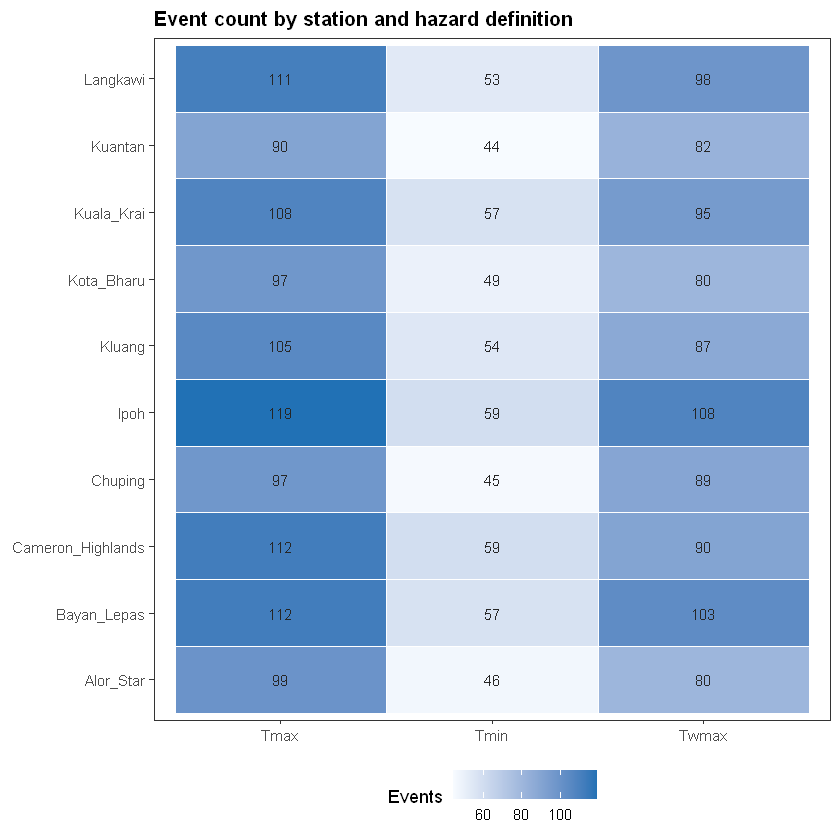

In [5]:
p_n <- ggplot(n_tab, aes(defn, station, fill = n)) +
  geom_tile(colour = "white") +
  geom_text(aes(label = n), size = 3.2, colour = "grey15") +
  scale_fill_gradient(low = "#F7FBFF", high = "#2171B5", name = "Events") +
  labs(x = NULL, y = NULL, title = "Event count by station and hazard definition") +
  theme_paper() + theme(panel.grid = element_blank())

save_fig(p_n, "S05_event_counts", 6.5, 4.5)
p_n

---

## 3. Table 1（续）：事件属性摘要

In [6]:
tab1 <- cat_ev %>%
  group_by(station, defn) %>%
  summarise(n = n(),
            mean_duration = round(mean(duration), 2),
            max_duration  = max(duration),
            mean_intensity = round(mean(intensity), 2),
            max_intensity  = round(max(intensity), 2),
            .groups = "drop") %>%
  arrange(station, defn)

print(as.data.frame(tab1), row.names = FALSE)

           station  defn   n mean_duration max_duration mean_intensity
         Alor_Star  Tmax  99          4.39           11           1.56
         Alor_Star  Tmin  46          3.93           10           2.11
         Alor_Star Twmax  80          4.45           10           1.94
       Bayan_Lepas  Tmax 112          4.49           11           1.68
       Bayan_Lepas  Tmin  57          4.09            9           2.19
       Bayan_Lepas Twmax 103          4.50           12           1.91
 Cameron_Highlands  Tmax 112          4.22           11           1.51
 Cameron_Highlands  Tmin  59          4.24           11           1.99
 Cameron_Highlands Twmax  90          4.43           12           1.77
           Chuping  Tmax  97          4.58           13           1.53
           Chuping  Tmin  45          4.09            9           2.22
           Chuping Twmax  89          4.26           12           1.81
              Ipoh  Tmax 119          4.45           18           1.68
      

In [7]:
# 三个定义的整体对比 —— 论文 Results 第一段就要写这个
cat_ev %>%
  group_by(defn) %>%
  summarise(n_events = n(),
            mean_duration = round(mean(duration), 2),
            median_duration = median(duration),
            mean_intensity = round(mean(intensity), 2),
            mean_severity  = round(mean(severity), 2),
            .groups = "drop") %>%
  print()

# A tibble: 3 × 6
  defn  n_events mean_duration median_duration mean_intensity mean_severity
  <chr>    <int>         <dbl>           <dbl>          <dbl>         <dbl>
1 Tmax      1050          4.42               4           1.6           4.47
2 Tmin       523          4.11               3           2.11          4.98
3 Twmax      912          4.34               4           1.83          4.74


---

## 4. 图：事件日历（甘特图）

把每个事件画成一条线段，颜色表示前期状态。**一眼就能看出事件在时间上是否聚集。**

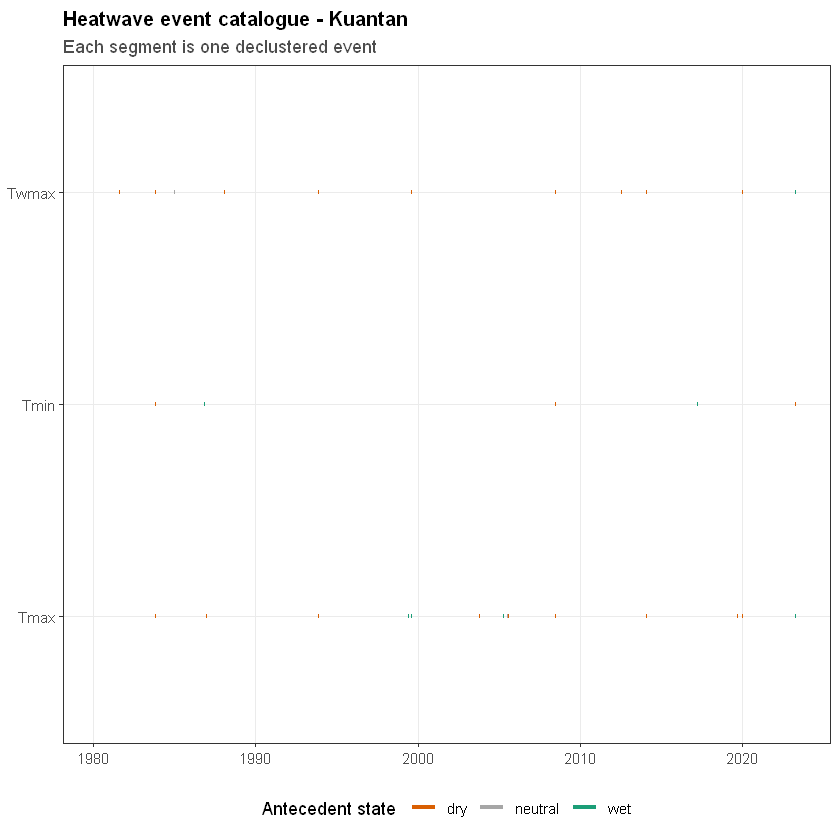

In [8]:
STATION <- "Kuantan"
sub <- cat_ev %>% filter(station == STATION) %>% arrange(start_date)

p_cal <- ggplot(sub, aes(x = start_date, xend = end_date,
                         y = defn, yend = defn, colour = state)) +
  geom_segment(linewidth = 1.4) +
  scale_colour_manual(values = c(dry = "#D95F02", neutral = "grey65", wet = "#1B9E77"),
                      na.value = "grey85") +
  labs(x = NULL, y = NULL, colour = "Antecedent state",
       title = paste("Heatwave event catalogue -", STATION),
       subtitle = "Each segment is one declustered event") +
  theme_paper()

save_fig(p_cal, "S05_event_calendar", 7, 3.6)
p_cal

> 🔍 **看什么**：如果干期（橙色）事件在特定年代聚集，说明前期降雨控制可能在增强。如果三种颜色均匀散布，说明控制是平稳的。

---

## 5. 非平稳性对事件数的影响

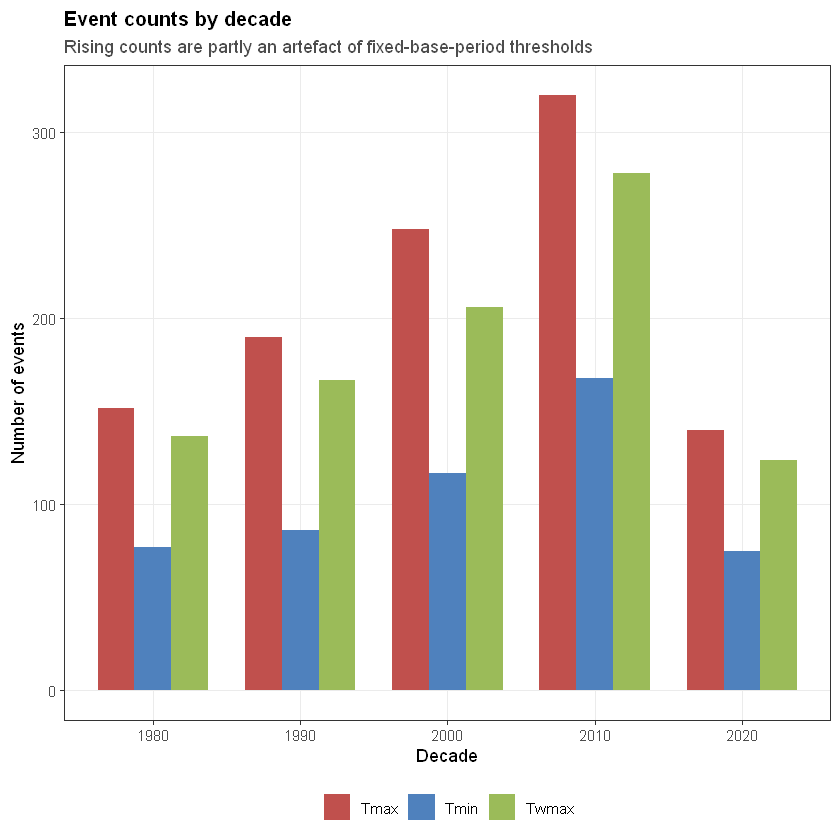

In [9]:
cat_ev$decade <- (cat_ev$start_year %/% 10) * 10

dec <- cat_ev %>%
  group_by(decade, defn) %>%
  summarise(n = n(), .groups = "drop")

p_dec <- ggplot(dec, aes(factor(decade), n, fill = defn)) +
  geom_col(position = "dodge", width = 0.75) +
  scale_fill_manual(values = c(Tmax = "#C0504D", Tmin = "#4F81BD", Twmax = "#9BBB59")) +
  labs(x = "Decade", y = "Number of events", fill = NULL,
       title = "Event counts by decade",
       subtitle = "Rising counts are partly an artefact of fixed-base-period thresholds") +
  theme_paper()

save_fig(p_dec, "S05_events_by_decade", 6.5, 4)
p_dec

> ⚠️ **这张图必须配一句解释**：事件数随年代上升，一部分是真实的气候信号，一部分是**固定阈值口径造成的伪信号**（S01 §7.3）。
> 论文里不能说「热浪增加了 X%」而不区分这两者。S14 会用时变阈值做拆解。

---

## 6. 保存 Table 1

In [10]:
write.csv(as.data.frame(tab1),
          file.path(PATHS$mres, "table1_event_summary.csv"),
          row.names = FALSE)
cat("已保存:", file.path(PATHS$mres, "table1_event_summary.csv"), "\n")

已保存: C:/Users/User/Desktop/Jz/UTM/UGRP/method_manual/results/table1_event_summary.csv 


---

## 7. 常见错误

| 错误 | 后果 |
|---|---|
| 不报告每格样本量 | 审稿人无法判断 copula 结果是否可信 |
| 把 10 个站的事件直接合并拟合 copula | 忽略了站间差异（应该分层或加随机效应） |
| 用事件数的时间趋势直接下气候结论 | 混淆气候信号与阈值口径 |
| 只画总事件数，不画日历 | 看不出聚集性 |

---

## 8. 自检问题

<details>
<summary>Q1：为什么 Tmin 定义的事件数通常少于 Tmax？</summary>

夜间最低气温的自相关更强、日际变率更小，超阈值后往往连续多日，因此「片段数」更少但每段更长。在模拟数据里 Tmin 只有 44 个事件（Kuantan），而 Tmax 有 90 个。
</details>

<details>
<summary>Q2：如果某站某定义只有 18 个事件，还能算 Kendall τ 吗？</summary>

能算，但标准误很大（约 ±0.15），且无法可靠估计尾部依赖。正确做法：报告 τ 的同时报告 n 和 bootstrap 区间，或在论文中标注为「探索性」。
</details>

<details>
<summary>Q3：事件日历上如果干期事件集中在 1997–1998 和 2015–2016，说明什么？</summary>

那是强 El Niño 年。说明前期降雨控制可能被大尺度环流调制 —— 这正是审稿人会问的「内生性」问题，S14 会用 ENSO 分层来回应。
</details>

---

## 下一步

**S06 · 前期降雨状态**：ARP 怎么算，为什么必须用百分位，中性带为什么存在。